# Data exploration

The first goal is to have a basic picture of the data. This includes knowing what we are predicting, class imbalance, if data is missing, etc.


## Load the data

In [1]:
import os
import csv
import numpy as np
import matplotlib.pyplot as plt

from helpers import load_csv_data

DATA_PATH = "dataset"

x_train, x_test, y_train, train_ids, test_ids = load_csv_data(DATA_PATH)

with open(os.path.join(DATA_PATH, "x_train.csv"), newline="") as f:
    feature_names = next(csv.reader(f))[1:]   # first column is Id (not a feature)

feature_index = {name: i for i, name in enumerate(feature_names)}


Let's print the first few rows of the tables:

In [2]:
for i in range(5):
    print(f"\nRow {i}:")
    for name, value in zip(feature_names[:10], x_train[i, :10]):
        print(f"{name:10s}: {value}")
    print("label:", y_train[i])


Row 0:
_STATE    : 53.0
FMONTH    : 11.0
IDATE     : 11162015.0
IMONTH    : 11.0
IDAY      : 16.0
IYEAR     : 2015.0
DISPCODE  : 1100.0
SEQNO     : 2015015629.0
_PSU      : 2015015629.0
CTELENUM  : nan
label: -1

Row 1:
_STATE    : 33.0
FMONTH    : 12.0
IDATE     : 12152015.0
IMONTH    : 12.0
IDAY      : 15.0
IYEAR     : 2015.0
DISPCODE  : 1200.0
SEQNO     : 2015004387.0
_PSU      : 2015004387.0
CTELENUM  : 1.0
label: -1

Row 2:
_STATE    : 20.0
FMONTH    : 10.0
IDATE     : 10202015.0
IMONTH    : 10.0
IDAY      : 20.0
IYEAR     : 2015.0
DISPCODE  : 1100.0
SEQNO     : 2015005638.0
_PSU      : 2015005638.0
CTELENUM  : 1.0
label: -1

Row 3:
_STATE    : 42.0
FMONTH    : 6.0
IDATE     : 6182015.0
IMONTH    : 6.0
IDAY      : 18.0
IYEAR     : 2015.0
DISPCODE  : 1100.0
SEQNO     : 2015004694.0
_PSU      : 2015004694.0
CTELENUM  : nan
label: -1

Row 4:
_STATE    : 24.0
FMONTH    : 11.0
IDATE     : 11062015.0
IMONTH    : 11.0
IDAY      : 6.0
IYEAR     : 2015.0
DISPCODE  : 1100.0
SEQNO     : 201

Let's now look at the shapes for each dataset:

In [3]:
print("x_train:", x_train.shape)
print("x_test: ", x_test.shape)
print("y_train:", y_train.shape)
print("Labels: ", np.unique(y_train))

x_train: (328135, 321)
x_test:  (109379, 321)
y_train: (328135,)
Labels:  [-1  1]


We have **328,135 training examples**, **109,379 test examples**, and **321 features**.

The target is binary: `-1` or `+1`.


## 1. Is the target balanced?

We want to know if the two classes are present in roughly equal amounts.

+1: 28,975 (8.83%)
-1: 299,160 (91.17%)
Accuracy if we always predict -1: 91.17%


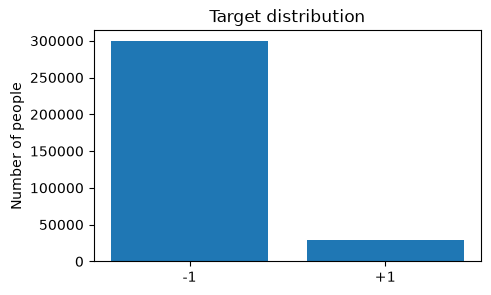

In [4]:
positive = y_train == 1

n_pos = np.sum(positive)
n_neg = len(y_train) - n_pos

print(f"+1: {n_pos:,} ({100 * n_pos / len(y_train):.2f}%)")
print(f"-1: {n_neg:,} ({100 * n_neg / len(y_train):.2f}%)")
print(f"Accuracy if we always predict -1: {100 * n_neg / len(y_train):.2f}%")

plt.figure(figsize=(5, 3))
plt.bar(["-1", "+1"], [n_neg, n_pos])
plt.ylabel("Number of people")
plt.title("Target distribution")
plt.show()


This means that **8.83%** of the training examples are positive.

If we were to naively predit `-1`, we would already get **91.17% training accuracy**. It is of course not a useful model, but this gives us an important reference and we showed that the classes are very imbalanced.

This already makes us think about a few methods we can use to prevent this, such as oversampling the `+1`, though this is just an initial thought.

## 2. How much data is missing?


Overall missing entries: 44.79%
Features with at least 50% missing: 147 / 321
Features with at least 90% missing: 99 / 321

10 most-missing features:
LADULT         99.99%
COLGHOUS       99.99%
PCDMDECN       99.95%
ASERVIST       99.93%
ASDRVIST       99.93%
ASNOSLEP       99.90%
ASINHALR       99.85%
ASTHMED3       99.85%
ASYMPTOM       99.85%
ASACTLIM       99.85%


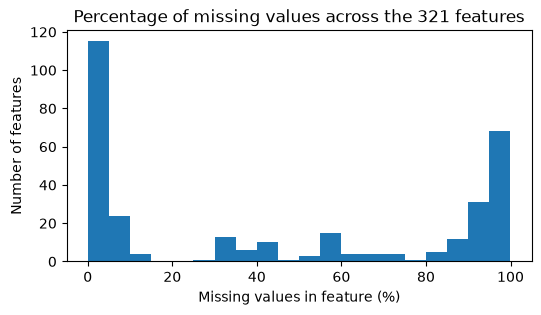

In [5]:
# missing_train contains 321 values (one for each feature), it represents the proportion of missing values in each feature
missing_train = np.isnan(x_train).mean(axis=0)

print(f"Overall missing entries: {100 * np.mean(missing_train):.2f}%")
print(f"Features with at least 50% missing: {np.sum(missing_train >= 0.50)} / {x_train.shape[1]}")
print(f"Features with at least 90% missing: {np.sum(missing_train >= 0.90)} / {x_train.shape[1]}")

order = np.argsort(missing_train)[::-1][:10]

print("\n10 most-missing features:")
for j in order:
    print(f"{feature_names[j]:12s}  {100 * missing_train[j]:6.2f}%")

plt.figure(figsize=(6, 3))
plt.hist(100 * missing_train, bins=20)
plt.xlabel("Missing values in feature (%)")
plt.ylabel("Number of features")
plt.title("Percentage of missing values across the 321 features")
plt.show()


We learn something important: about 44.8% of all feature entries are NaN, with 147 / 321 features are at least half missing.

What this means for us: we need to decide how to handle these missing values, and ignoring them is not a good idea considering this matter affects a large part of the dataset.

## 3. What kind of features are these?

The CSV is numeric, but some of these numbers are just labels for some categories (e.g., GENHLTH: 1 = Excellent, 2 = Very good, 3 = Good, 4 = Fair, 5 = Poor, 7 = Don't know/Not sure, 9 = Refused).

Here, `GENHLTH` represents general health, `_AGEG5YR` represents age groups, and `_BMI5CAT` represents BMI categories.


In [6]:
for name in ["GENHLTH", "_AGEG5YR", "_BMI5CAT"]:
    col = x_train[:, feature_index[name]]
    values = np.unique(col[~np.isnan(col)])
    print(f"{name:10s}: {values}")


GENHLTH   : [1. 2. 3. 4. 5. 7. 9.]
_AGEG5YR  : [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14.]
_BMI5CAT  : [1. 2. 3. 4.]


We indeed see that in this example, `GENHLTH`, `_AGEG5YR`, and `_BMI5CAT` only take a small set of coded values.

So our preprocessing steps have to respect the meaning of each feature. We should therefore not treat every column as an ordinary continuous number, since this could lose information or create misleading numerical relationships.

## 4. Does age already show a relationship with the target?

Here, we plot the percentage of `+1` labels inside each age group.


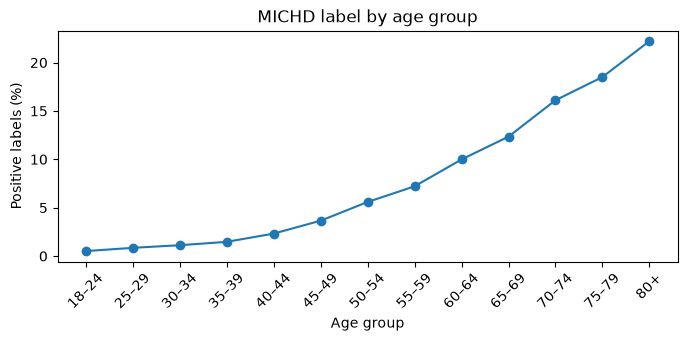

18–24: 0.51% positive
80+:   22.22% positive


In [7]:
def positive_rate_by_code(feature, codes):
    col = x_train[:, feature_index[feature]]
    rates = []
    for value in codes:
        mask = col == value
        rates.append(100 * np.mean(positive[mask]))
    return np.array(rates)

age_codes = np.arange(1, 14)
age_labels = [
    "18–24", "25–29", "30–34", "35–39", "40–44", "45–49",
    "50–54", "55–59", "60–64", "65–69", "70–74", "75–79", "80+"
]

age_rates = positive_rate_by_code("_AGEG5YR", age_codes)

plt.figure(figsize=(8, 3))
plt.plot(age_labels, age_rates, marker="o")
plt.xticks(rotation=45)
plt.xlabel("Age group")
plt.ylabel("Positive labels (%)")
plt.title("MICHD label by age group")
plt.show()

print(f"18–24: {age_rates[0]:.2f}% positive")
print(f"80+:   {age_rates[-1]:.2f}% positive")


The positive rate rises from about **0.5% for ages 18–24** to **22.2% for ages 80+**.

So there is already a very clear signal in a simple, understandable feature.


## 5. What about general health?

Let's use the same feature as before: `GENHLTH`.


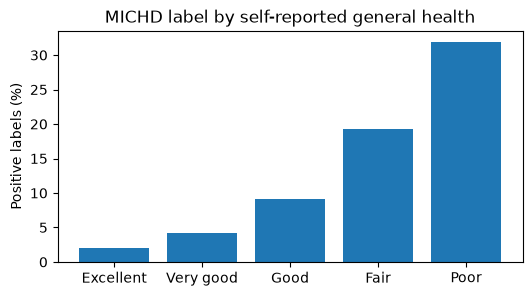

Excellent :  2.05%
Very good :  4.24%
Good      :  9.13%
Fair      : 19.29%
Poor      : 31.90%


In [8]:
health_codes = np.arange(1, 6)
health_labels = ["Excellent", "Very good", "Good", "Fair", "Poor"]
health_rates = positive_rate_by_code("GENHLTH", health_codes)

plt.figure(figsize=(6, 3))
plt.bar(health_labels, health_rates)
plt.ylabel("Positive labels (%)")
plt.title("MICHD label by self-reported general health")
plt.show()

for label, rate in zip(health_labels, health_rates):
    print(f"{label:10s}: {rate:5.2f}%")


Once again we found a strong pattern: the positive rate goes from about 2.1% for people reporting excellent health to about 31.9% for people reporting poor health.

At this point we now know that in this dataset simple features already contain useful predictive information.


## 6. Can the survey structure itself reveal the answer?

This is important because some questions are only asked after certain previous answers.


In [9]:
harehab = x_train[:, feature_index["HAREHAB1"]]
answered = ~np.isnan(harehab)

print("HAREHAB1 answered:", np.sum(answered))
print(f"Positive rate when answered: {100 * np.mean(positive[answered]):.2f}%")
print(f"Positive rate when blank:    {100 * np.mean(positive[~answered]):.2f}%")


HAREHAB1 answered: 773
Positive rate when answered: 100.00%
Positive rate when blank:    8.61%


`HAREHAB1` is a BRFSS question about rehabilitation following a heart attack. It is answered for 773 training examples, and every one of those examples has label `+1`.

This could be a sign for **data leakage** because this information is connected to the event we are trying to predict, which may be present in the inputs.

This does not mean we automatically delete the feature, but it should be something discussed.


## 7. Do train and test look similar?


Largest difference between train and test: 0.40%


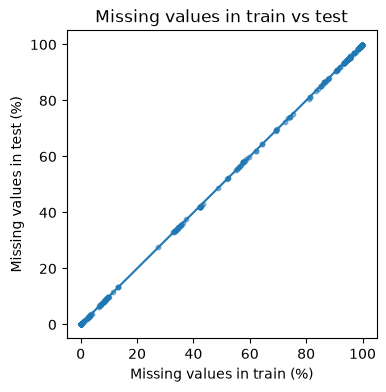

In [12]:
missing_test = np.isnan(x_test).mean(axis=0)
gap = np.abs(missing_train - missing_test)

print(f"Largest difference between train and test: {100 * np.max(gap):.2f}%")

plt.figure(figsize=(4, 4))
plt.scatter(100 * missing_train, 100 * missing_test, s=10, alpha=0.5)
plt.plot([0, 100], [0, 100])
plt.xlabel("Missing values in train (%)")
plt.ylabel("Missing values in test (%)")
plt.title("Missing values in train vs test")
plt.show()

Each dot represents one feature. Most dots lie almost exactly on the diagonal, meaning that each feature has about the same amount of missing data in the training and test sets.

The largest difference is only about 0.4%, so train and test seem very similar in this respect.

## What we learned

1. The classes are very unbalanced: about **91% are `-1`**.
2. A large part of the dataset is missing.
3. Some features are **categories written as numbers**, not real measurements.
4. **Age** and **general health** seem useful for prediction.
5. `HAREHAB1` may reveal the answer too directly, so we need to be careful with it.
6. Train and test look very similar in terms of missing values.

The next steps are therefore to handle missing and categorical values, split the training data into train/validation sets, and start testing simple models.